# 千葉の自転車盗：実行例

これは解説用の実行例です。提出用は新しい空のNotebookを作成してください。

2025年度教材から引き継いだ千葉県警公開CSV・9,943件。発生日は2019〜2024年と不明を含む。最新の事件情報ではありません。

出典：https://www.police.pref.chiba.jp/seisoka/safe-life_publicspace-statistics_00002.html

## 1. 準備
`bicycle-theft.csv` をNotebookと同じフォルダに保存。標準ライブラリのルートは追加インストール不要。

## 2. CSVを読む

csv.DictReaderは、各行を「列名: 値」の辞書にします。listで全行をまとめ、lenで件数を確認します。

In [1]:
# 読み込むファイルを設定する（Notebookと同じフォルダに保存）
filename = "bicycle-theft.csv"

# Python標準のcsvで読む。追加インストールは不要
import csv
with open(filename, encoding="utf-8-sig", newline="") as file:
    incidents = list(csv.DictReader(file))

# 1行が1件の事件。件数を確認する
len(incidents)

9943

## 3. 1件の内容を見る

incidentsはリスト、incidents[0]は最初の事件の辞書。列名をキーに値を取り出します。列名一覧は list(incidents[0]) で確認。

In [2]:
# 最初の事件から、必要な列を選んで確認する
row = incidents[0]
row["市区町村（発生地）"], row["発生時（始期）"], row["施錠関係"]

('千葉市中央区', '23', '施錠した')

## 4. forで数える

counts.get(label, 0)は、登録済みなら件数、未登録なら0。その値に1を足して保存します。事件の総数と集計の合計が一致するか確かめよう。

In [3]:
# 集計したい列を選ぶ
column = "施錠関係"
counts = {}

# 同じ値が出てくるたびに、件数を1増やす
for row in incidents:
    label = row[column]
    counts[label] = counts.get(label, 0) + 1

counts

{'施錠した': 3162, '施錠せず': 6781}

## 5. 市区町村を絞る

==は一致の比較。appendはリストの末尾へ1件追加。市名を変えて再実行し、件数を比較してみよう。

In [4]:
# 調べたい市区町村を指定する
city = "柏市"
selected = []

# 条件に合う事件だけ、新しいリストへ入れる
for row in incidents:
    if row["市区町村（発生地）"] == city:
        selected.append(row)

len(selected)

691

## 6. ランキング

CounterはPython標準ライブラリ。未登録のキーは0から数えられます。most_common(5)は件数の多い上位5組を返します。件数は人口や駐輪台数で補正した被害率ではありません。

In [5]:
column = "市区町村（発生地）"
top_n = 5

# Counterは標準ライブラリ。未登録の値は0件から数える
from collections import Counter
counts = Counter()
for row in incidents:
    counts[row[column]] += 1

# 件数の多い上位5組を取り出す
top_places = counts.most_common(top_n)
top_places

[('船橋市', 1263), ('市川市', 872), ('柏市', 691), ('松戸市', 678), ('千葉市中央区', 656)]

## 7. pandasなしで棒を描く

文字の繰り返しで簡単な棒グラフを作れます。棒1個は100件。//は整数の商、:,は3桁ごとの桁区切りです。棒は切り捨てなので、正確な数値も必ず添えます。

In [6]:
# 棒1個を何件にするか設定する
scale = 100

# 正確な件数も表示する（棒の長さは100件未満を切り捨て）
for place, count in top_places:
    bar = "█" * (count // scale)
    print(f"{place}: {bar} {count:,}件")

船橋市: ████████████ 1,263件
市川市: ████████ 872件
柏市: ██████ 691件
松戸市: ██████ 678件
千葉市中央区: ██████ 656件


## 発展：年月ごとの件数

日付不明は別に数えます。同じ「9月」でも年が違えば別の集計。既存CSVのため、毎月・毎年が完全な期間とは限りません。

In [7]:
# 日付の先頭6文字（年・月）で数える。違う年の同じ月を混ぜない
counts_by_month = {}
unknown_dates = 0
for row in incidents:
    date = row["発生年月日（始期）"]
    if len(date) == 8 and date.isdigit():
        month = date[:6]
        counts_by_month[month] = counts_by_month.get(month, 0) + 1
    else:
        unknown_dates += 1

# 年月の文字列を並べると、時間順になる
for month in sorted(counts_by_month):
    print(month, counts_by_month[month])
print("Unknown dates:", unknown_dates)

201905 1
202104 1
202203 1
202204 2
202207 1
202211 1
202301 4
202302 1
202303 2
202305 2
202306 2
202307 6
202308 5
202309 4
202310 14
202311 21
202312 198
202401 616
202402 568
202403 678
202404 758
202405 810
202406 824
202407 1020
202408 938
202409 980
202410 942
202411 866
202412 584
Unknown dates: 93


## 発展：時間帯

不明を0時に変えないでください。発生時（始期）は警察データの項目名です。事件が起きた正確な時刻とは限りません。

In [8]:
# 時刻が不明の事件は、0時に変えず別に数える
hours = {}
unknown_hours = 0
for row in incidents:
    value = row["発生時（始期）"]
    if value.isdigit():
        hour = int(value)
        hours[hour] = hours.get(hour, 0) + 1
    else:
        unknown_hours += 1

for hour in sorted(hours):
    print(f"{hour:02}:00", hours[hour])
print("Unknown hours:", unknown_hours)

00:00 167
01:00 74
02:00 32
03:00 23
04:00 30
05:00 113
06:00 333
07:00 919
08:00 675
09:00 411
10:00 433
11:00 371
12:00 508
13:00 390
14:00 388
15:00 473
16:00 695
17:00 859
18:00 875
19:00 606
20:00 500
21:00 413
22:00 311
23:00 229
Unknown hours: 115


## 任意：pandasで同じ集計

pandas・Matplotlibが使える人向け。使えなくても上のルートで課題を完成できます。

[pandas公式ガイド](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)

value_counts()は値ごとの件数を降順に並べ、head(5)は先頭5件を表示します。

In [9]:
# pandasが使える場合の別ルート。同じCSVを読む
filename = "bicycle-theft.csv"
import pandas as pd
df = pd.read_csv(filename)

# 列を1本選び、値ごとの件数を多い順に表示する
df["市区町村（発生地）"].value_counts().head(5)

市区町村（発生地）
船橋市       1263
市川市        872
柏市         691
松戸市        678
千葉市中央区     656
Name: count, dtype: int64

## 任意：pandasとforを組み合わせる

pandasを使う場合も、レポートにforを含めます。citiesの市名を自分で選び直し、結果を比較しよう。内側の条件は、列の値がcityと一致する行を選びます。

In [10]:
# 比較する市区町村を、先に設定する
cities = ["柏市", "松戸市", "流山市"]

# 市名をforで順に変え、条件に合う行だけ数える
for city in cities:
    selected_df = df[df["市区町村（発生地）"] == city]
    print(city, len(selected_df))

柏市 691
松戸市 678
流山市 302


## 任意：Matplotlibの棒グラフ

同じデータを使った実際の出力です。環境ごとの日本語フォント問題を避けるためラベルだけ英訳しています。

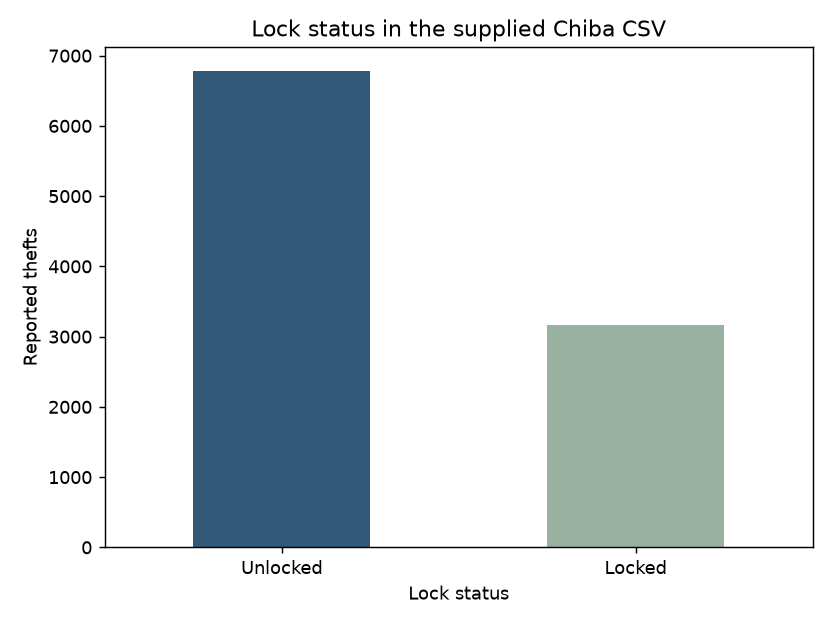

In [11]:
# グラフの文字は英語にして、追加フォントを不要にする
import matplotlib.pyplot as plt
lock_counts = df["施錠関係"].value_counts()
lock_counts.index = lock_counts.index.map({
    "施錠せず": "Unlocked", "施錠した": "Locked"
})

# 棒グラフを描く
lock_counts.plot.bar(color=["#315876", "#98b1a1"], rot=0)
plt.xlabel("Lock status")
plt.ylabel("Reported thefts")
plt.title("Lock status in the supplied Chiba CSV")
plt.tight_layout()
plt.show()

## 問いに戻る

件数の違いから何が言えますか？ 分母（駐輪台数など）がないため、盗まれる確率や施錠の効果は計算できません。

緯度・経度はありません。架空の座標を作って事件地点として表示しないこと。地図は任意。地域の代表点を使う場合は「地域別の集計」と明記してください。

発生日の不明93件、時刻の不明115件を含みます。除外した場合は、何件除外したかを説明してください。